In [1]:

from google.colab import files

uploaded = files.upload()


Saving hcvdat0.csv to hcvdat0.csv


In [2]:

import os

print("Files available in Colab:")
print(os.listdir("/content"))


Files available in Colab:
['.config', 'hcvdat0.csv', 'sample_data']


In [3]:

import pandas as pd

df = pd.read_csv("/content/hcvdat0.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (615, 14)


,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [4]:

print("Column names:")
print(df.columns.tolist())

print("\nData types and non-missing values:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())


Column names:
['Unnamed: 0', 'Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']

Data types and non-missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    object 
 2   Age         615 non-null    int64  
 3   Sex         615 non-null    object 
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-null    float64
 8   BIL         615 non-null    float64
 9   CHE         615 non-null    float64
 10  CHOL        605 non-null    float64
 11  CREA        615 non-null    float64
 12  GGT         615 non-null    float64
 13  PROT        614 non-null    float64
dtypes: float64(10), int64(2), object(2)
memory usage: 67.4+ KB

Missing va

,0
Unnamed: 0,0
Category,0
Age,0
Sex,0
ALB,1
ALP,18
ALT,1
AST,0
BIL,0
CHE,0


What we have learned so far
- The dataset contains 615 records and 14 columns.
- Category is our target variable, containing the outcome categories we want to study.
- Unnamed: 0 appears to be a record identifier. We should exclude it from model predictors because identifiers generally do not provide meaningful clinical information.
- Age, Sex, and the 10 laboratory measurements provide 12 candidate predictors.
- Missing values appear in ALB (1), ALP (18), ALT (1), CHOL (10), and PROT (1): 31 missing cells across these five columns.
- We should not delete all rows containing missing values automatically. We will assess the missingness and use appropriate imputation within the model-training pipeline to avoid data leakage.

In [5]:

# Step 2: Inspect the target variable and data quality

import pandas as pd

# 1. Count records in each outcome category
print("1. Outcome category counts:")
display(df["Category"].value_counts().rename("Record Count").to_frame())

# 2. Calculate percentages for each category
print("\n2. Outcome category percentages:")
category_percentages = (
    df["Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
    .to_frame()
)
display(category_percentages)

# 3. Check duplicate rows
print("\n3. Exact duplicate rows:", df.duplicated().sum())

# 4. Check duplicate record identifiers
print("4. Duplicate identifiers:", df["Unnamed: 0"].duplicated().sum())

# 5. Display all unique target labels
print("\n5. Unique outcome labels:")
print(sorted(df["Category"].unique()))

# 6. Check missing values as percentages
print("\n6. Missing-value percentages:")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing_summary[missing_summary["Missing Count"] > 0])


1. Outcome category counts:


,Record Count
Category,
0=Blood Donor,533
3=Cirrhosis,30
1=Hepatitis,24
2=Fibrosis,21
0s=suspect Blood Donor,7



2. Outcome category percentages:


,Percentage
Category,
0=Blood Donor,86.67
3=Cirrhosis,4.88
1=Hepatitis,3.90
2=Fibrosis,3.41
0s=suspect Blood Donor,1.14



3. Exact duplicate rows: 0
4. Duplicate identifiers: 0

5. Unique outcome labels:
['0=Blood Donor', '0s=suspect Blood Donor', '1=Hepatitis', '2=Fibrosis', '3=Cirrhosis']

6. Missing-value percentages:


,Missing Count,Missing Percentage
ALB,1,0.16
ALP,18,2.93
ALT,1,0.16
CHOL,10,1.63
PROT,1,0.16


What these results mean
- Class imbalance is substantial. The blood donor category contains 533 records, while the smallest category contains only 7.
- Accuracy alone will be insufficient. A model that predicts every record as a blood donor would achieve 86.67% accuracy, yet it would fail to identify any of the other four categories.
- No exact duplicate rows were found. The identifier column is also unique in every record. This is reassuring, but it does not prove that every record is clinically independent or error-free.
- Missingness is relatively limited. The largest proportion of missing values is in ALP (2.93%), followed by CHOL (1.63%). We will retain incomplete records initially and handle missing predictor values within our analysis pipeline.

EDA

In [6]:

# Step 4.1: Prepare a working copy for exploratory analysis

eda_df = df.drop(columns=["Unnamed: 0"]).copy()

numeric_features = [
    "Age", "ALB", "ALP", "ALT", "AST", "BIL",
    "CHE", "CHOL", "CREA", "GGT", "PROT"
]

print("Analysis dataset shape:", eda_df.shape)
print("Remaining columns:", eda_df.columns.tolist())
print("Original dataset unchanged:", "Unnamed: 0" in df.columns)


Analysis dataset shape: (615, 13)
Remaining columns: ['Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
Original dataset unchanged: True


In [7]:

# Step 4.2: Descriptive statistics for numerical features

display(
    eda_df[numeric_features]
    .describe()
    .round(2)
)

print("Sex distribution:")
display(
    eda_df["Sex"]
    .value_counts()
    .rename("Record Count")
    .to_frame()
)


,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
count,615.00,614.00,597.00,614.00,615.00,615.00,615.00,605.00,615.00,615.00,614.00
mean,47.41,41.62,68.28,28.45,34.79,11.40,8.20,5.37,81.29,39.53,72.04
std,10.06,5.78,26.03,25.47,33.09,19.67,2.21,1.13,49.76,54.66,5.40
min,19.00,14.90,11.30,0.90,10.60,0.80,1.42,1.43,8.00,4.50,44.80
25%,39.00,38.80,52.50,16.40,21.60,5.30,6.94,4.61,67.00,15.70,69.30
50%,47.00,41.95,66.20,23.00,25.90,7.30,8.26,5.30,77.00,23.30,72.20
75%,54.00,45.20,80.10,33.08,32.90,11.20,9.59,6.06,88.00,40.20,75.40
max,77.00,82.20,416.60,325.30,324.00,254.00,16.41,9.67,1079.10,650.90,90.00


Sex distribution:


,Record Count
Sex,
m,377
f,238


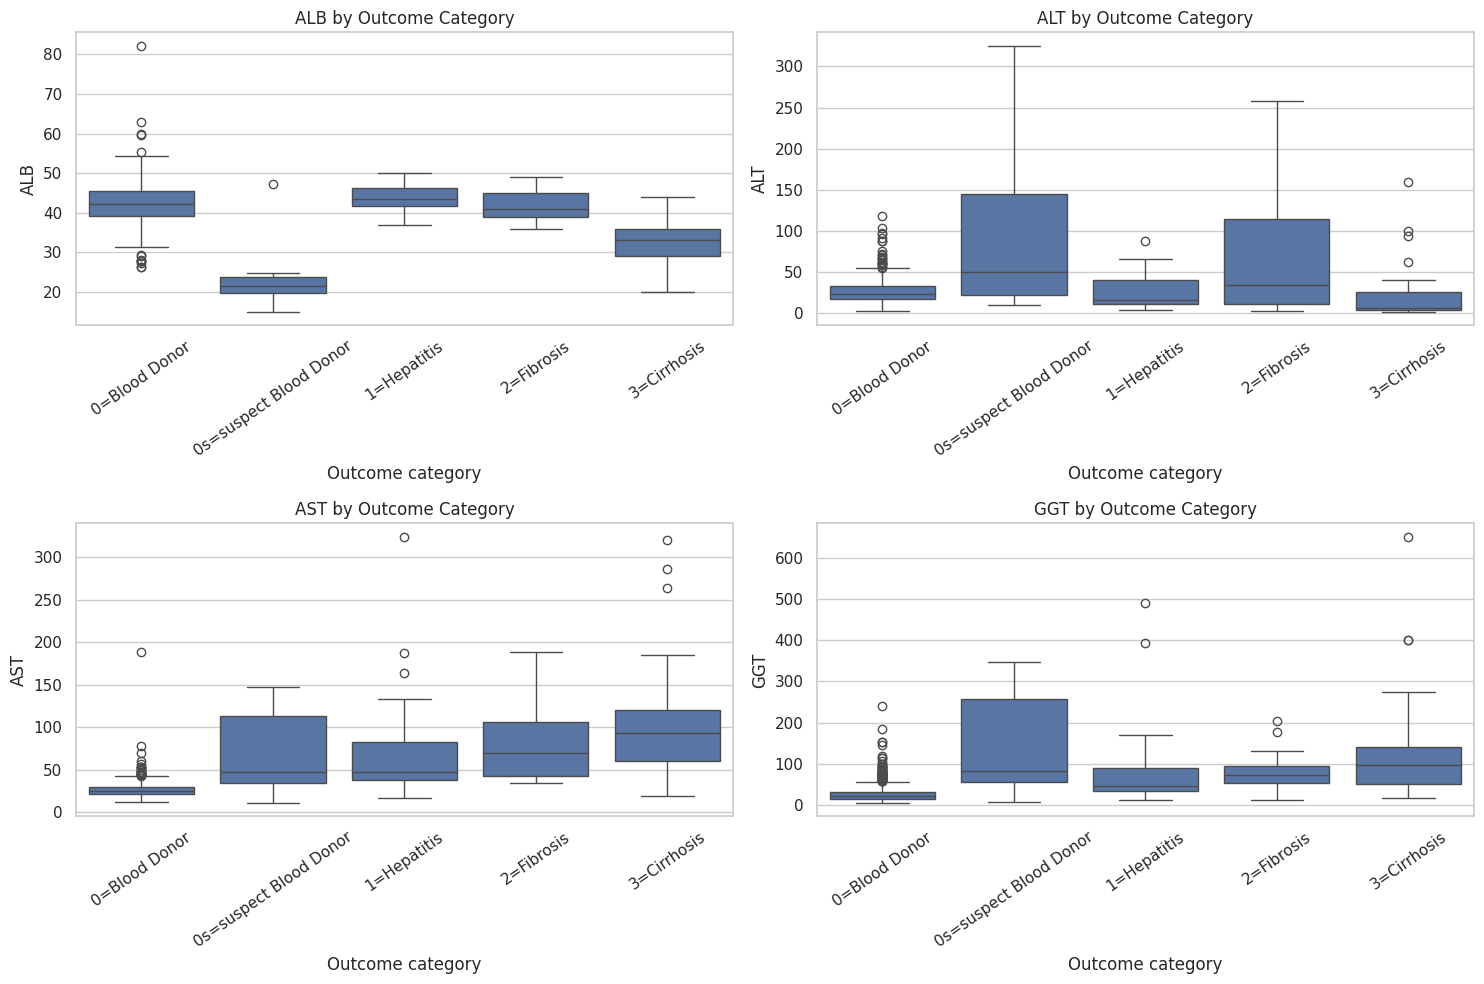

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

features_to_plot = ["ALB", "ALT", "AST", "GGT"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.boxplot(
        data=eda_df,
        x="Category",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Outcome Category")
    ax.set_xlabel("Outcome category")
    ax.set_ylabel(feature)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


,Skewness
CREA,15.17
BIL,8.39
GGT,5.63
ALT,5.51
AST,4.94
ALP,4.65
CHOL,0.38
Age,0.27
CHE,-0.11
ALB,-0.18


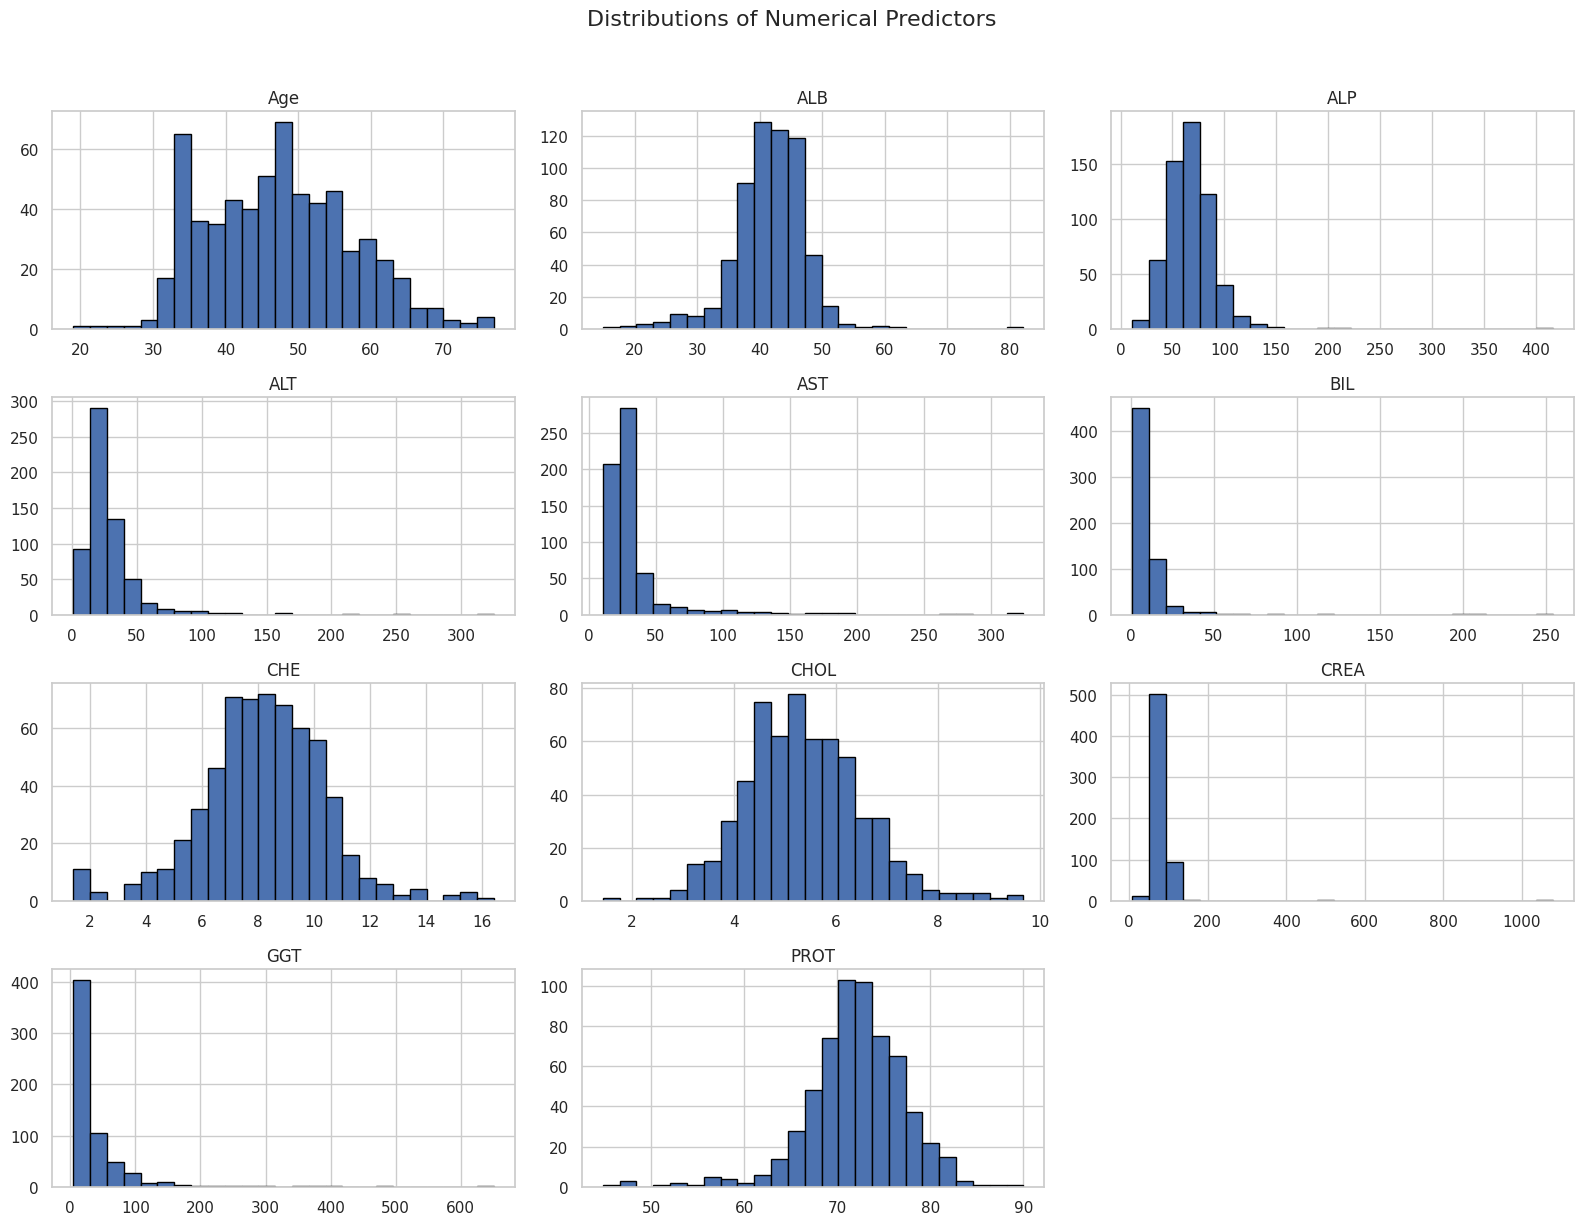

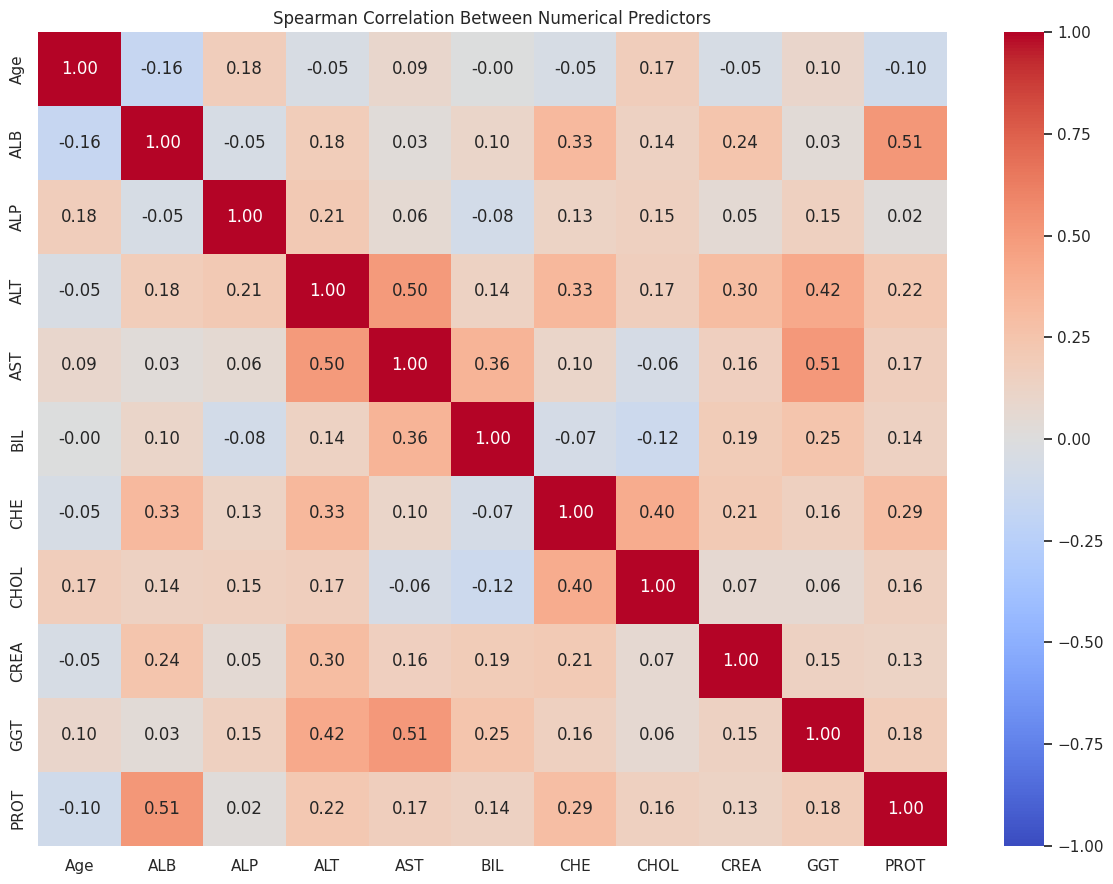

In [9]:

# Step 6.1: Examine skewness in numerical predictors

skewness = (
    eda_df[numeric_features]
    .skew()
    .sort_values(ascending=False)
    .rename("Skewness")
    .to_frame()
)

display(skewness.round(2))

# Step 6.2: Plot numerical feature distributions

eda_df[numeric_features].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Predictors",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

# Step 6.3: Examine correlations between numerical predictors

correlation_matrix = eda_df[numeric_features].corr(
    method="spearman"
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Numerical Predictors")
plt.tight_layout()
plt.show()


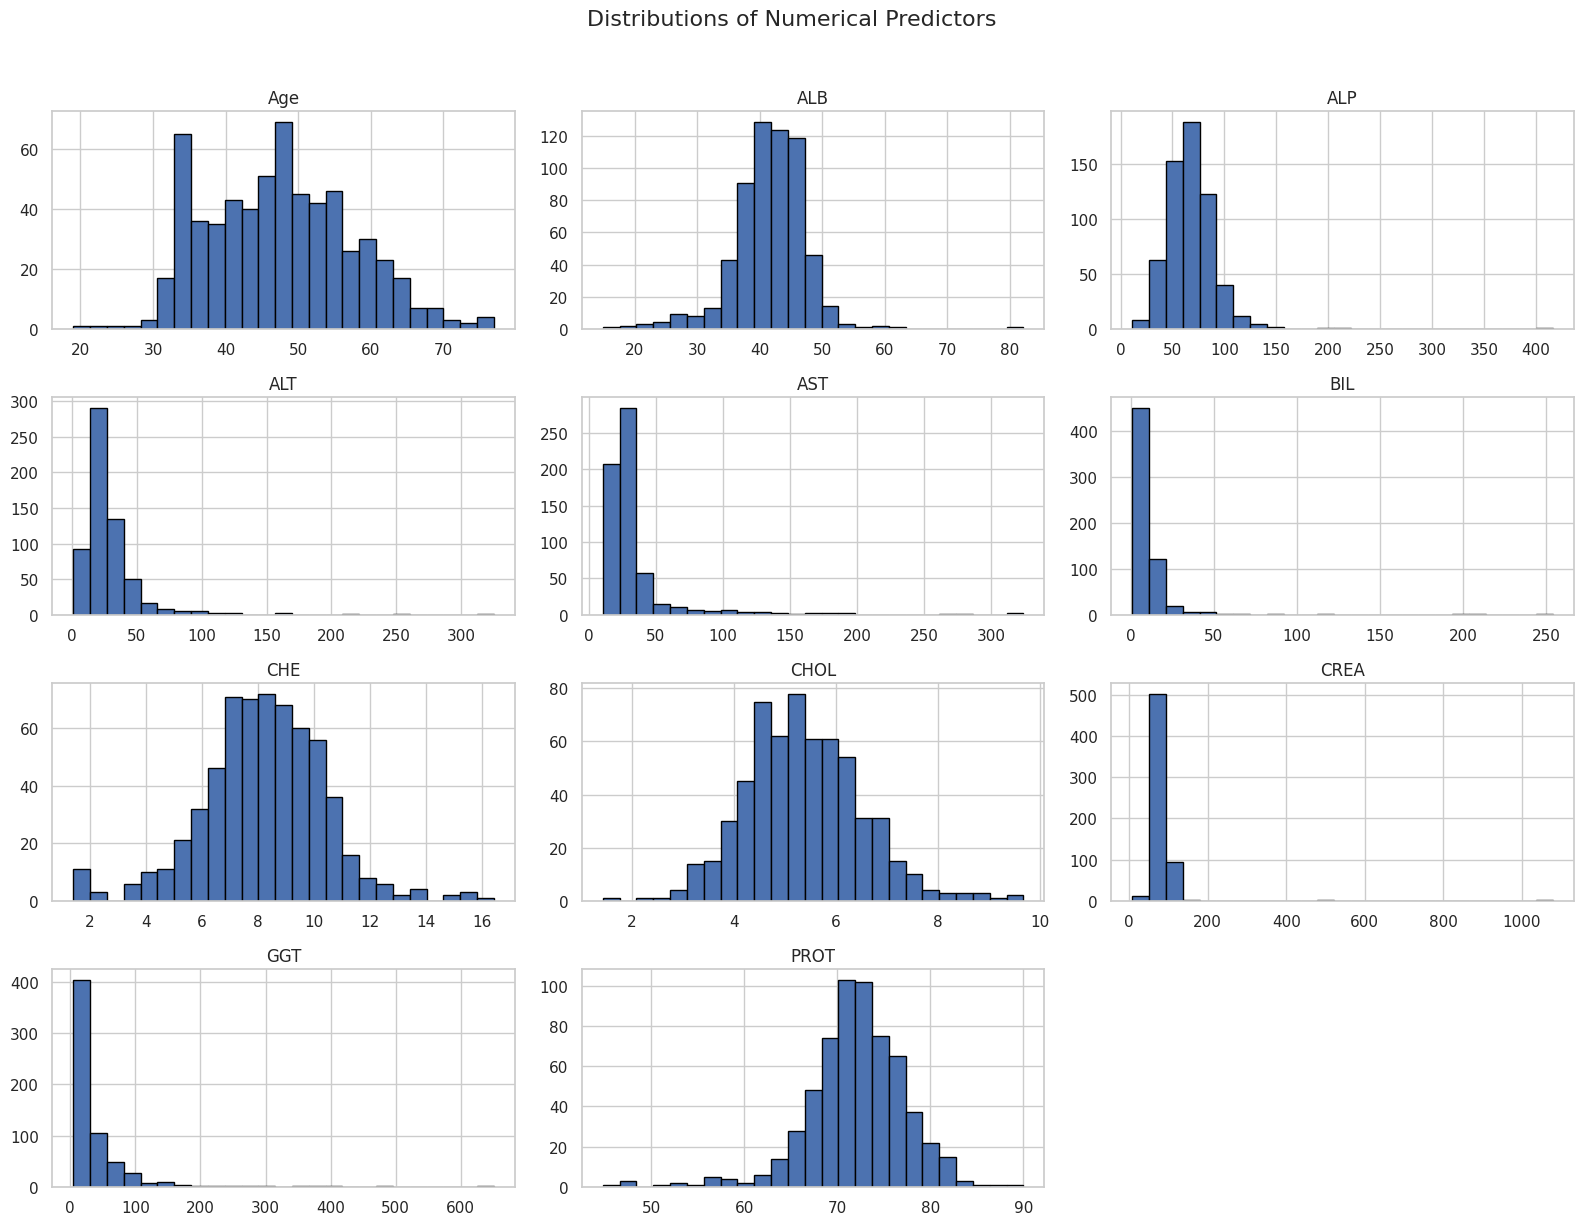

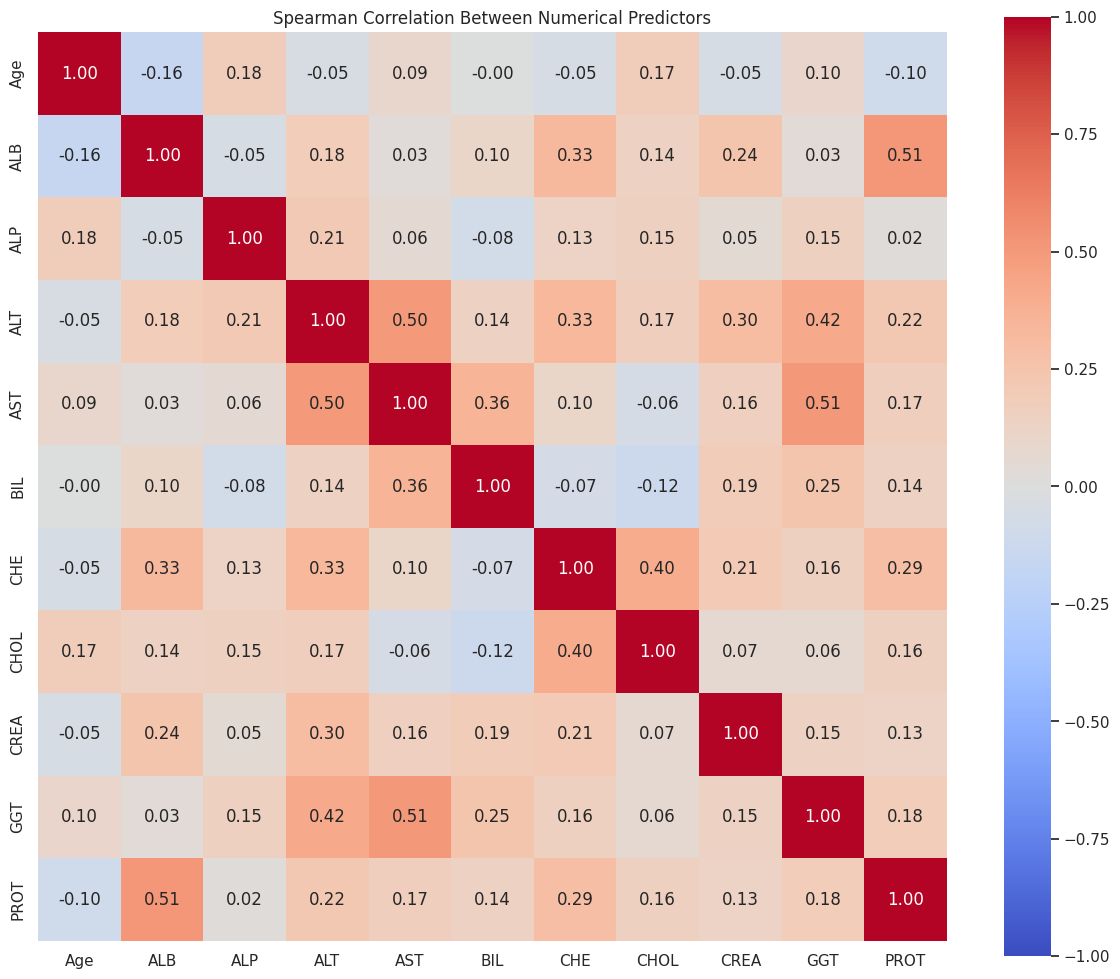

Predictor pairs with absolute Spearman correlation >= 0.70:


,Feature 1,Feature 2,Spearman Correlation


In [10]:

# Step 7: Generate and save clearer EDA figures

import matplotlib.pyplot as plt
import seaborn as sns

# A. Histograms of all numerical predictors
axes = eda_df[numeric_features].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Predictors",
    fontsize=16,
    y=1.02
)
plt.tight_layout()
plt.savefig("hcv_feature_histograms.png", dpi=300, bbox_inches="tight")
plt.show()

# B. Spearman correlation heatmap
corr = eda_df[numeric_features].corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Spearman Correlation Between Numerical Predictors")
plt.tight_layout()
plt.savefig("hcv_spearman_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

# C. Identify predictor pairs with stronger correlations
upper = corr.where(
    __import__("numpy").triu(
        __import__("numpy").ones(corr.shape), k=1
    ).astype(bool)
)

strong_pairs = (
    upper.stack()
    .rename("Spearman Correlation")
    .reset_index()
    .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"})
)

strong_pairs = strong_pairs[
    strong_pairs["Spearman Correlation"].abs() >= 0.70
].sort_values(
    "Spearman Correlation",
    key=abs,
    ascending=False
)

print("Predictor pairs with absolute Spearman correlation >= 0.70:")
display(strong_pairs.round(3))


In [11]:

# Step 8: Compare numerical predictors across outcome categories

from scipy.stats import kruskal
import pandas as pd

# 1. Median values for each numerical predictor by category
category_medians = (
    eda_df.groupby("Category")[numeric_features]
    .median()
    .round(2)
)

print("Median numerical measurements by outcome category:")
display(category_medians)

# 2. Kruskal-Wallis tests for each numerical predictor
test_results = []

for feature in numeric_features:
    groups = [
        group[feature].dropna().values
        for _, group in eda_df.groupby("Category", observed=True)
    ]

    # Run only if every category has observations
    if all(len(group) > 0 for group in groups):
        statistic, p_value = kruskal(*groups)

        test_results.append({
            "Feature": feature,
            "Kruskal-Wallis H": statistic,
            "p-value": p_value
        })

kruskal_results = pd.DataFrame(test_results)

# Apply Benjamini-Hochberg correction for multiple comparisons
from statsmodels.stats.multitest import multipletests

kruskal_results["Adjusted p-value (BH)"] = multipletests(
    kruskal_results["p-value"],
    method="fdr_bh"
)[1]

kruskal_results = kruskal_results.sort_values(
    "Adjusted p-value (BH)"
)

print("\nKruskal-Wallis tests with Benjamini-Hochberg correction:")
display(kruskal_results.round(5))


Median numerical measurements by outcome category:


,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
Category,,,,,,,,,,,
0=Blood Donor,47.0,42.2,66.70,23.10,24.8,6.9,8.35,5.40,78.00,21.40,72.20
0s=suspect Blood Donor,55.0,21.6,106.00,49.20,46.7,4.9,5.33,4.30,52.00,83.00,47.80
1=Hepatitis,37.0,43.5,34.60,15.20,47.2,13.0,9.51,5.06,72.25,45.55,73.65
2=Fibrosis,51.0,41.0,39.55,34.00,70.0,13.0,8.59,4.58,71.40,72.20,76.10
3=Cirrhosis,56.0,33.0,80.05,5.65,92.9,34.0,3.42,3.87,68.50,96.35,70.00



Kruskal-Wallis tests with Benjamini-Hochberg correction:


,Feature,Kruskal-Wallis H,p-value,Adjusted p-value (BH)
4,AST,161.65225,0.00000,0.00000
9,GGT,112.38315,0.00000,0.00000
5,BIL,98.66227,0.00000,0.00000
1,ALB,70.07174,0.00000,0.00000
6,CHE,69.15073,0.00000,0.00000
2,ALP,66.31268,0.00000,0.00000
7,CHOL,59.47468,0.00000,0.00000
0,Age,34.36824,0.00000,0.00000
10,PROT,28.32798,0.00001,0.00001
3,ALT,24.80899,0.00005,0.00006


In [12]:

# Step 10: Examine Sex distribution across outcome categories

import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact

# Contingency table
sex_table = pd.crosstab(
    eda_df["Category"],
    eda_df["Sex"]
)

print("Sex counts by outcome category:")
display(sex_table)

print("\nSex percentages within each outcome category:")
display(
    pd.crosstab(
        eda_df["Category"],
        eda_df["Sex"],
        normalize="index"
    ).mul(100).round(2)
)

# Pearson chi-square test
chi2, p_value, dof, expected = chi2_contingency(sex_table)

print("\nPearson chi-square test")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.8g}")
print(f"Minimum expected cell count: {expected.min():.4f}")
print(
    "Expected cells below 5:",
    (expected < 5).sum(),
    "out of",
    expected.size
)


Sex counts by outcome category:


Sex,f,m
Category,,
0=Blood Donor,215,318
0s=suspect Blood Donor,1,6
1=Hepatitis,4,20
2=Fibrosis,8,13
3=Cirrhosis,10,20



Sex percentages within each outcome category:


Sex,f,m
Category,,
0=Blood Donor,40.34,59.66
0s=suspect Blood Donor,14.29,85.71
1=Hepatitis,16.67,83.33
2=Fibrosis,38.10,61.90
3=Cirrhosis,33.33,66.67



Pearson chi-square test
Chi-square statistic: 7.6402
Degrees of freedom: 4
P-value: 0.10568156
Minimum expected cell count: 2.7089
Expected cells below 5: 2 out of 10


In [13]:

# Step 12: Monte Carlo exact-test approximation for the 5 x 2 table

import numpy as np
from scipy.stats import random_table

observed = sex_table.to_numpy()

# Use 100,000 simulations for a reproducible approximation
n_simulations = 100_000
rng = np.random.default_rng(640)

# Generate tables with the same row and column totals
simulated_tables = random_table.rvs(
    observed.sum(axis=1),
    observed.sum(axis=0),
    size=n_simulations,
    random_state=rng
)

# Pearson chi-square statistic for the observed table
chi2_observed = chi2_contingency(
    observed,
    correction=False
)[0]

# Expected counts under independence
expected_counts = np.outer(
    observed.sum(axis=1),
    observed.sum(axis=0)
) / observed.sum()

# Compute Pearson statistics for simulated tables
simulated_chi2 = (
    (simulated_tables - expected_counts) ** 2
    / expected_counts
).sum(axis=(1, 2))

# Monte Carlo p-value, with the standard +1 correction
exceedances = np.sum(simulated_chi2 >= chi2_observed)
p_monte_carlo = (exceedances + 1) / (n_simulations + 1)

print("Observed Pearson chi-square:", round(chi2_observed, 4))
print("Monte Carlo simulations:", n_simulations)
print("Random seed: 640")
print("Monte Carlo p-value:", round(p_monte_carlo, 5))
print(
    "Monte Carlo standard error (approx.):",
    round(
        np.sqrt(
            p_monte_carlo * (1 - p_monte_carlo)
            / n_simulations
        ),
        5
    )
)


Observed Pearson chi-square: 7.6402
Monte Carlo simulations: 100000
Random seed: 640
Monte Carlo p-value: 0.10478
Monte Carlo standard error (approx.): 0.00097
